In [2]:
%env CUDA_DEVICE_ORDER=PCI_BUS_ID
%env CUDA_VISIBLE_DEVICES=0
%pylab inline
%load_ext autoreload
%autoreload 2

env: CUDA_DEVICE_ORDER=PCI_BUS_ID
env: CUDA_VISIBLE_DEVICES=0
%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


In [3]:
import json
import torch
import numpy as np
import pandas as pd
from tqdm import tqdm
import os
from pathlib import Path
from matplotlib.colors import TwoSlopeNorm
import matplotlib.pyplot as plt
import matplotlib as mpl
from openTSNE import TSNE
import colorcet as cc

/gpfs01/berens/user/pgivehchian/ssl_neuron/.venv39/lib64/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
from ssl_neuron.datasets import GraphDataset
from ssl_neuron.utils import plot_neuron, plot_tsne, neighbors_to_adjacency_torch, compute_eig_lapl_torch_batch
from ssl_neuron.graphdino import create_model

In [5]:
TRIAL = "trial7"

#### Load config

In [6]:
config = json.load(open(f'../configs/{TRIAL}.json'))

#### Load model + checkpoint

In [7]:
cell_meta = pd.read_csv(os.path.join(config['data']['path'], 'cell_meta.csv'))
cell_meta['cell_id'] = cell_meta['cell_id'].astype(str)

#### Load dataset

In [13]:
dset = GraphDataset(config, mode='all')

100%|██████████| 3690/3690 [01:57<00:00, 31.50it/s]


In [14]:
feat, neigh, cell_id = dset.__getsingleitem__(0)

#### Plot neuron

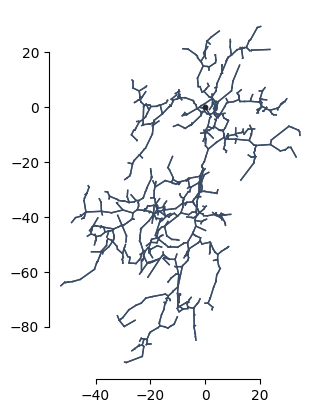

In [92]:
plot_neuron(neigh, feat)

<ErrorbarContainer object of 3 artists>

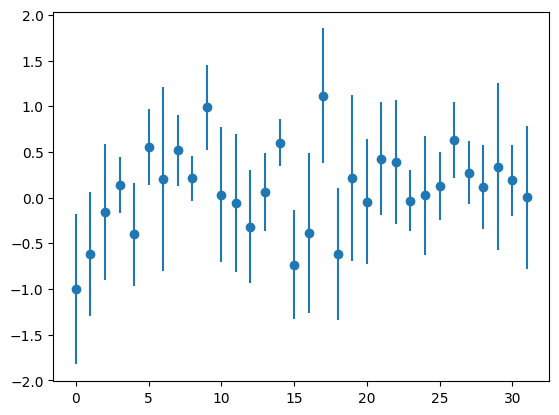

In [ ]:
plt.scatter(np.arange(config['model']['dim']), cell_meta['latents'].mean(axis=0))

plt.errorbar(np.arange(config['model']['dim']), cell_meta['latents'].mean(axis=0), yerr = cell_meta['latents'].std(axis=0), fmt='none')

In [10]:
cell_meta = pd.read_csv(os.path.join(config['trainer']['latents_dir'], f'{TRIAL}.csv'))

In [11]:
# Load IDs
data_dir = config['data']['path']

train_ids = np.load(os.path.join(data_dir, 'train_ids.npy')).astype(str)
val_ids = np.load(os.path.join(data_dir, 'val_ids.npy')).astype(str)
test_ids = np.load(os.path.join(data_dir, 'test_ids.npy')).astype(str)

# Create mapping
split_map = {
    **dict.fromkeys(train_ids, 'train'),
    **dict.fromkeys(val_ids, 'val'),
    **dict.fromkeys(test_ids, 'test')
}

# Assign split to each cell
cell_meta['split'] = cell_meta['cell_id'].astype(str).map(split_map)

# Check results
print(cell_meta['split'].value_counts(dropna=False))

train    2797
val       428
test      356
NaN       249
Name: split, dtype: int64


In [12]:
cell_meta["latent"] = cell_meta["latent"].apply(
    lambda x: np.fromstring(x.strip("[]"), sep=" ")
    if isinstance(x, str) and x.strip()
    else np.array([])
)

In [13]:
def get_celltype_colors(cell_meta):
    celltypes = sorted(cell_meta['celltype_final'].dropna().unique())

    colors = cc.glasbey[:len(celltypes)]

    color_dict = dict(zip(celltypes, colors))

    return color_dict

color_dict = get_celltype_colors(cell_meta)

In [14]:
def plot_tsne(
    cell_meta,
    unknown_labels=True,
    color_by='celltype',
    perplexity=30,
    random=True,
    color_dict=None
):

    if unknown_labels:
        plot_df = cell_meta.copy()
    else:
        plot_df = cell_meta[cell_meta['celltype_final'].notna()].copy()

    X = np.stack(plot_df['latent'].values).astype(np.float32)

    print("Embedding shape:", X.shape)
    print("Embedding dtype:", X.dtype)

    # Run t-SNE
    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=42,
        initialization='random',
        learning_rate=200.0,
        n_jobs=-1
    )

    X_tsne = np.array(tsne.fit(X))

    plot_df['TSNE1'] = X_tsne[:, 0]
    plot_df['TSNE2'] = X_tsne[:, 1]

    if random:
        plot_df = plot_df.sample(frac=1).reset_index(drop=True)

    fig, ax = plt.subplots(
        figsize=(8, 5) if color_by != 'celltype' else (12, 5)
    )

    # 1. Color by cell type
    if color_by == 'celltype':

        if color_dict is None:
            color_dict = get_celltype_colors(plot_df)

        point_colors = plot_df['celltype_final'].map(color_dict)

        if unknown_labels:
            point_colors = point_colors.fillna('lightgrey')

        ax.scatter(
            plot_df['TSNE1'],
            plot_df['TSNE2'],
            c=point_colors,
            s=15,
            alpha=0.8,
            zorder=2
        )

        from matplotlib.lines import Line2D

        legend_elements = [
            Line2D(
                [0], [0],
                marker='o',
                color='w',
                label=str(celltype),
                markerfacecolor=color,
                markersize=6
            )
            for celltype, color in color_dict.items()
        ]

        if unknown_labels:
            legend_elements.append(
                Line2D(
                    [0], [0],
                    marker='o',
                    color='w',
                    label='Unknown',
                    markerfacecolor='lightgrey',
                    markersize=6
                )
            )

        ax.legend(
            handles=legend_elements,
            title='Cell Type',
            bbox_to_anchor=(1.02, 1),
            loc='upper left',
            ncol=2,
            fontsize=8,
            markerscale=1.5
        )

    # 2. Color by a continuous variable
    elif color_by in plot_df.columns and color_by != 'none':

        values = plot_df[color_by].to_numpy(dtype=float)

        vmin, vmax = np.nanpercentile(values, [2, 98])
        vcenter = np.nanmean(values)

        norm = TwoSlopeNorm(
            vmin=vmin,
            vcenter=vcenter,
            vmax=vmax
        )

        cmap = mpl.colormaps['RdBu_r']

        if random:
            order = np.random.permutation(len(plot_df))
        else:
            order = np.arange(len(plot_df))

        sc = ax.scatter(
            plot_df['TSNE1'].to_numpy()[order],
            plot_df['TSNE2'].to_numpy()[order],
            c=values[order],
            cmap=cmap,
            norm=norm,
            s=15,
            alpha=0.8
        )

        cbar = fig.colorbar(sc, ax=ax)
        cbar.set_label(color_by)

    # 3. Single color
    elif color_by == 'none':

        ax.scatter(
            plot_df['TSNE1'],
            plot_df['TSNE2'],
            color='steelblue',
            s=15,
            alpha=0.7
        )

    else:
        raise ValueError(
            f"Unknown color_by='{color_by}'. "
            "Use 'celltype', 'none', or a numerical column name."
        )

    ax.set_xlabel('t-SNE 1')
    ax.set_ylabel('t-SNE 2')
    ax.set_title(f't-SNE of Neuron Embeddings (colored by {color_by})')

    plt.tight_layout()
    plt.show()

    return plot_df

Embedding shape: (3225, 32)
Embedding dtype: float32


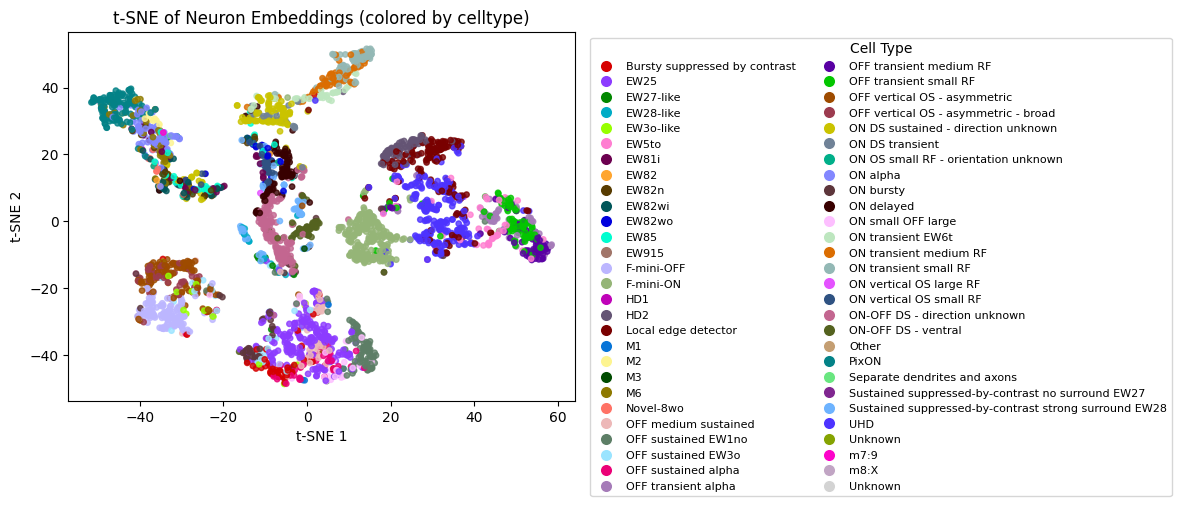

In [25]:
# plot_df = plot_tsne(cell_meta, unknown_labels=False, color_by='celltype')

plot_df = plot_tsne(cell_meta[cell_meta['split'].isin(['train', 'val'])], unknown_labels=True, color_dict=color_dict, color_by='celltype')

# plot_df = plot_tsne(cell_meta, color_by='none')

# plot_df = plot_tsne(cell_meta[cell_meta['split'] == 'train'], color_dict=color_dict, color_by='soma_z')


Training losses:
[6.79347754 6.64635086 5.99772263 4.81353951 3.36419582 2.40339947
 1.70811057 1.23867881 0.95192909 0.8010717  0.72552413 0.66804117
 0.63934654 0.61212283 0.60167485 0.60359246 0.56743914 0.56087703
 0.56595021 0.56419909 0.55212653 0.53815269 0.52948588 0.51020247
 0.51879114 0.48695767 0.49690151 0.47680199 0.47638315 0.46673959
 0.45499021 0.43871877 0.43126416 0.42155319 0.43175602 0.40999994
 0.41062602 0.3970713  0.39747533 0.39559481 0.38412356 0.37377959
 0.36888766 0.36484954 0.36296114 0.35870504 0.35957763 0.34292811
 0.34840912 0.34663332 0.33203885 0.32293943 0.32716846 0.33398756
 0.31646964 0.31697053 0.30579761 0.29714167 0.30283275 0.29129183
 0.30231583 0.28835672 0.29384565 0.2837165  0.27483526 0.28210843
 0.27214935 0.28228992 0.27639875 0.26121613 0.25604624 0.25331965
 0.25587541 0.25255147 0.24801874 0.26884025 0.24894789 0.24344766
 0.25980148 0.24970417 0.24874246 0.25359359 0.25804076 0.24619335
 0.24383587 0.2405681  0.23107147 0.22119676 

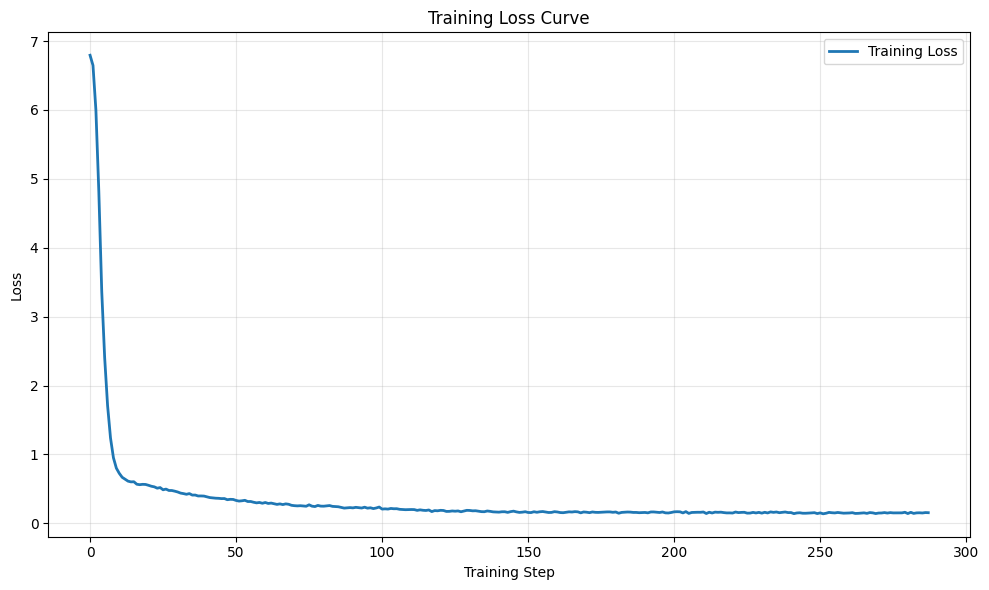

In [16]:
loss_path = Path("..") / Path(config['trainer']['losses_dir']) / Path(TRIAL) / "training_loss.npy"
losses = np.load(loss_path)

print("Training losses:")
print(losses)

print(f"Number of training steps: {len(losses)}")
print(f"Initial loss: {losses[0]:.6f}")
print(f"Final loss: {losses[-1]:.6f}")
print(f"Minimum loss: {np.min(losses):.6f}")

plt.figure(figsize=(10, 6))
plt.plot(losses, label="Training Loss", linewidth=2)

plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.title("Training Loss Curve")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Data Analysis

### z means

In [ ]:
z_means = []

for _, row in tqdm(cell_meta.iterrows(), total=len(cell_meta)):

    cell_id = int(row['cell_id'])

    feature_path = os.path.join(
        config['data']['path'],
        'skeletons',
        str(cell_id),
        'features.npy'
    )

    if os.path.exists(feature_path):

        features = np.load(feature_path)
        z_values = features[:, 2]
        z_mean = np.nanmean(z_values)

    else:
        print(f"Missing features: {cell_id}")
        z_mean = np.nan

    z_means.append(z_mean)

cell_meta['z_mean'] = z_means

  0%|          | 0/3830 [00:00<?, ?it/s]

100%|██████████| 3830/3830 [00:02<00:00, 1828.70it/s]


Embedding shape: (3225, 32)
Embedding dtype: float32


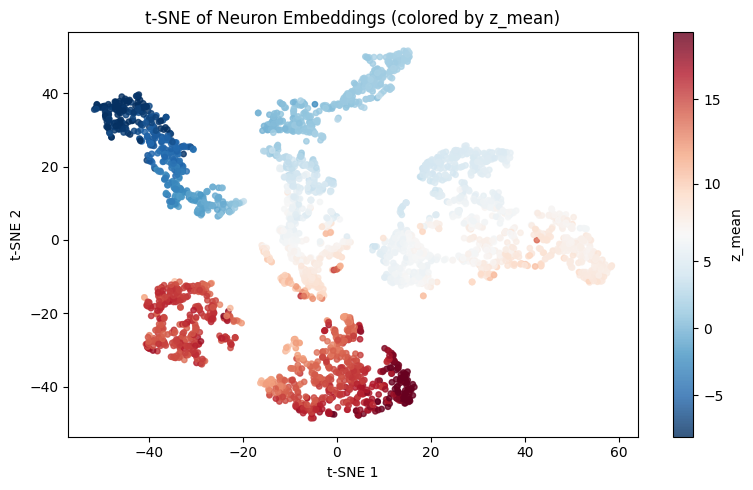

In [27]:
plot_df = plot_tsne(cell_meta[cell_meta['split'].isin(['train', 'val'])], unknown_labels=True, color_by='z_mean')

Embedding shape: (3690, 32)
Embedding dtype: float32


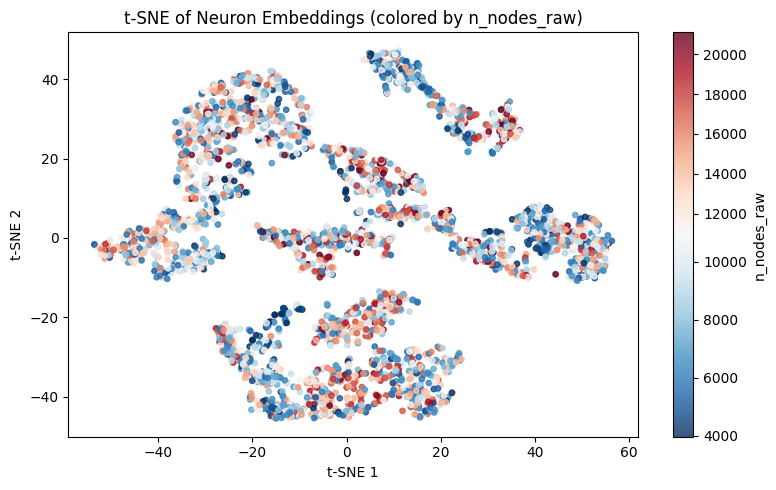

In [25]:
plot_df = plot_tsne(cell_meta, unknown_labels=True, color_by='n_nodes_raw')

In [156]:
overlapping_types = [
    "OFF sustained EW1no",
    "OFF sustained alpha",
    "OFF sustained EW3o",
    "ON bursty",
    "Bursty suppressed by contrast"
]